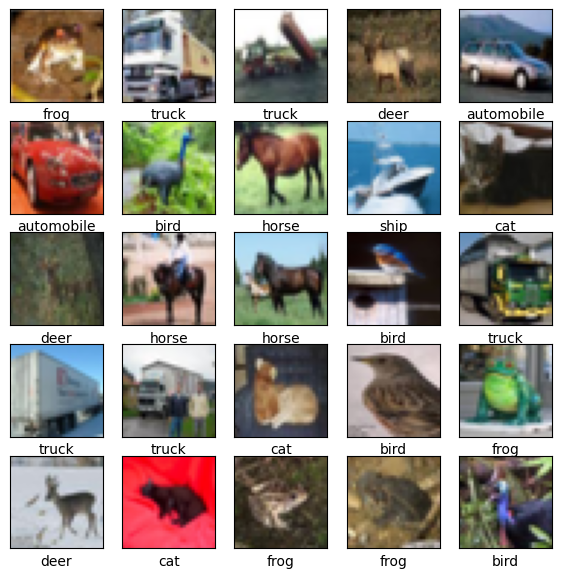

In [39]:
from keras.datasets import cifar10
import matplotlib.pyplot as plt
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

plt.figure(figsize=(7,7))
class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(class_names[train_labels[i][0]])
    plt.imshow(train_images[i])

plt.show()

In [19]:
from keras import models 
from keras import layers
from keras.utils import to_categorical
from keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

network = models.Sequential()
network.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(32,32,3)))
network.add(MaxPooling2D(pool_size=(2, 2)))
network.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2, 2)))
network.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2, 2)))
network.add(Flatten())
network.add(Dense(64, activation='relu'))
network.add(Dense(10, activation='softmax'))

In [20]:
network.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [22]:
network.fit(
    train_images,
    train_labels,
    epochs=25,
    batch_size=128
)

Epoch 1/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.7441 - loss: 0.7412
Epoch 2/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.7544 - loss: 0.7147
Epoch 3/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7631 - loss: 0.6863
Epoch 4/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7726 - loss: 0.6577
Epoch 5/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7782 - loss: 0.6379
Epoch 6/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.7844 - loss: 0.6150
Epoch 7/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7956 - loss: 0.5905
Epoch 8/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8057 - loss: 0.5629
Epoch 9/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.8120 - loss: 0.5433
Epoch 10/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.8162 - loss: 0.5279
Epoch 11/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.8226 - loss: 0.5104
Epoch 12/25
391/391 ━━━━━━━━━━

In [25]:
test_loss, test_acc = network.evaluate(
    test_images,
    test_labels
)
network.save('model-cifar.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6999 - loss: 1.2002


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


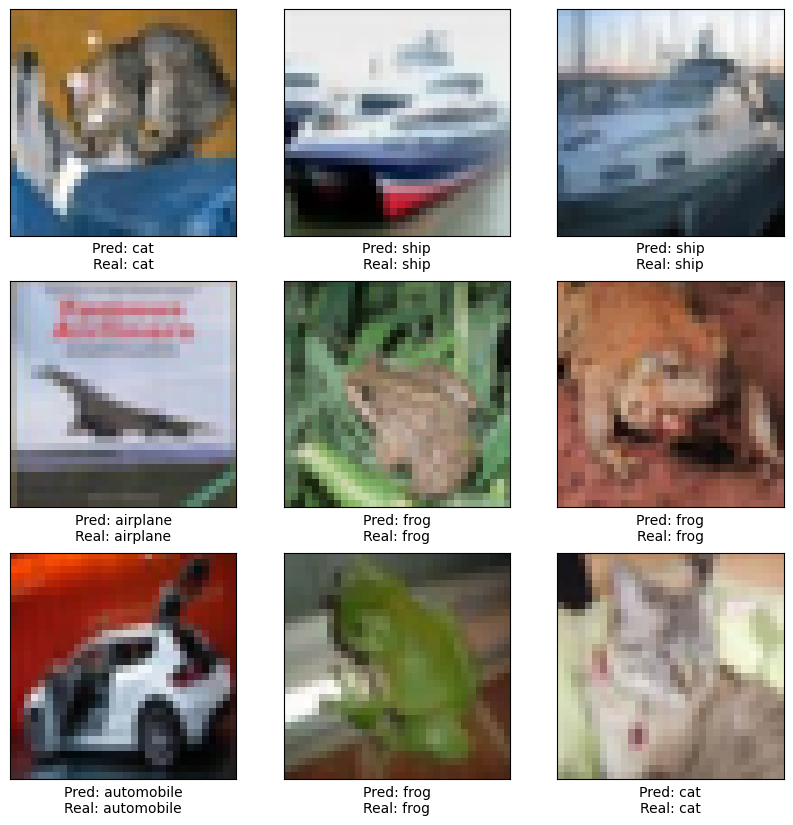

In [30]:
import numpy as np

predictions = network.predict(test_images)
plt.figure(figsize=(7,7))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(test_images[i])
    predicted_label = np.argmax(predictions[i])
    true_label = np.argmax(test_labels[i])

    plt.xlabel(
        "Pred: " + class_names[predicted_label] +
        "\nReal: " + class_names[true_label]
    )

    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

plt.show()